# Practical 11 — Air Quality Visualization

Create sample air-quality readings and use line, bar, box and scatter plots to explore AQI and pollutant trends.

**Run the cells from top to bottom.** The dataset is generated inside this notebook before the practical begins.

## 1. Install / import requirements

If a package is missing, run `!pip install pandas numpy matplotlib seaborn scikit-learn statsmodels openpyxl requests xgboost` in a notebook cell. Most environments already have the common packages.

In [1]:
from pathlib import Path
Path('data').mkdir(exist_ok=True)


## 2. Create the required dataset

This is the relevant part of `make_data.py`, placed here so the notebook is self-contained.

In [2]:
# Create one year of synthetic air-quality readings.
import numpy as np, pandas as pd
rng=np.random.default_rng(42); n=365
dates=pd.date_range("2024-01-01",periods=n)
pm25=80+40*np.cos((np.arange(n)-15)/365*2*np.pi)+rng.normal(0,12,n)
pm10=pm25*1.6+rng.normal(0,15,n)
aqi=pd.DataFrame({"Date":dates,"PM2.5":pm25.round(1),"PM10":pm10.round(1),
 "CO":rng.uniform(.4,2.5,n).round(2),"AQI":(pm25*1.8+rng.normal(0,8,n)).round()})
aqi.to_csv("data/City_Air_Quality.csv",index=False)
print("Created data/City_Air_Quality.csv")


Created data/City_Air_Quality.csv


## 3. Practical implementation

The following cells perform the analysis and show the output.

        Date  PM2.5   PM10    CO    AQI
0 2024-01-01  122.3  218.0  1.89  215.0
1 2024-01-02  106.4  159.0  0.72  192.0
2 2024-01-03  128.0  192.5  0.50  237.0
3 2024-01-04  130.4  211.7  0.69  236.0
4 2024-01-05   95.9  166.1  2.33  167.0
                                Date       PM2.5        PM10          CO  \
count                            365  365.000000  365.000000  365.000000   
mean   2024-07-01 00:00:00.000000256   79.892055  126.547945    1.460712   
min              2024-01-01 00:00:00   15.600000   10.200000    0.400000   
25%              2024-04-01 00:00:00   52.100000   85.500000    0.920000   
50%              2024-07-01 00:00:00   79.800000  127.400000    1.470000   
75%              2024-09-30 00:00:00  107.800000  168.200000    2.000000   
max              2024-12-30 00:00:00  144.400000  243.600000    2.500000   
std                              NaN   30.775274   51.317354    0.618036   

              AQI  
count  365.000000  
mean   143.843836  
min     29.0000

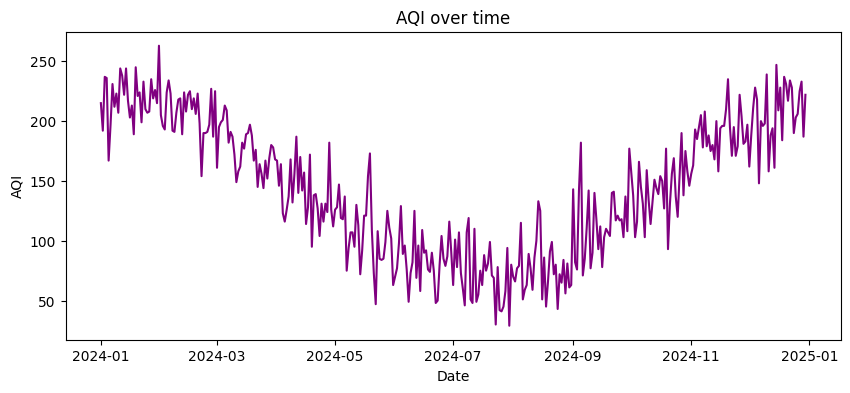

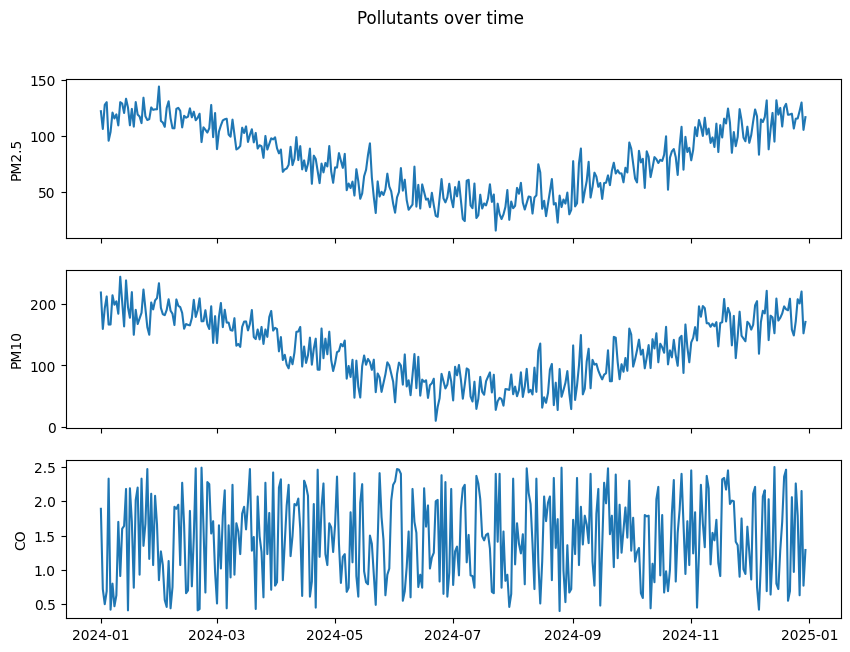

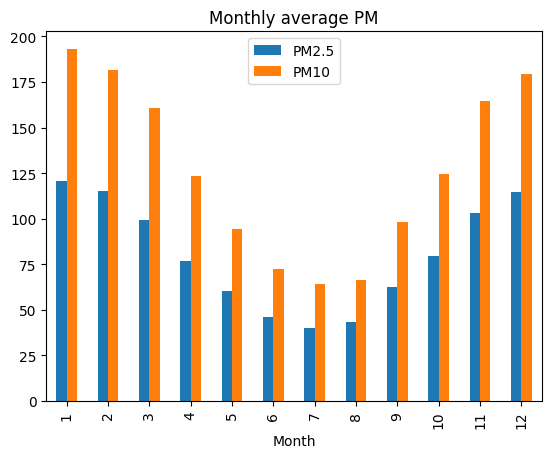

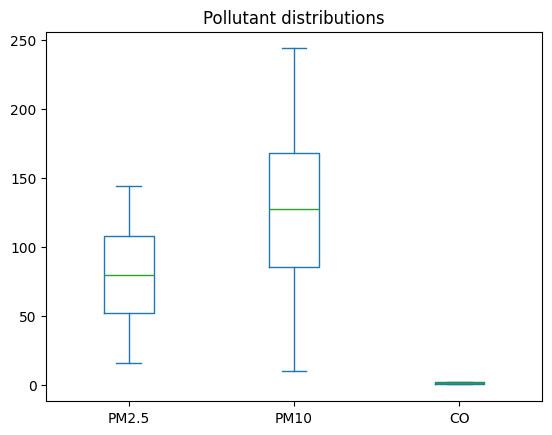

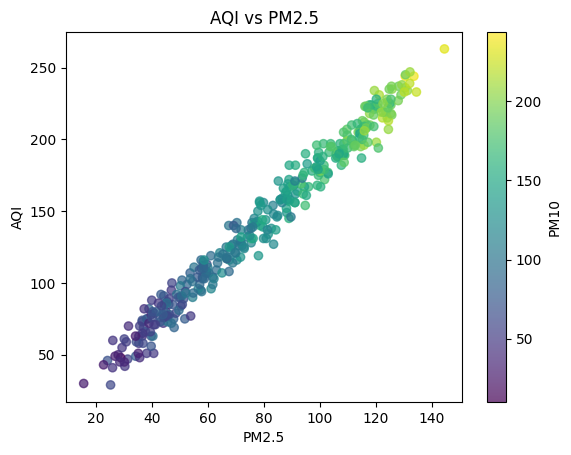

In [3]:
import pandas as pd, matplotlib.pyplot as plt

df = pd.read_csv("data/City_Air_Quality.csv", parse_dates=["Date"])
print(df.head(), df.describe(), sep="\n")

plt.figure(figsize=(10, 4)); plt.plot(df.Date, df.AQI, color="purple")           # overall trend
plt.title("AQI over time"); plt.xlabel("Date"); plt.ylabel("AQI"); plt.show()

fig, ax = plt.subplots(3, 1, figsize=(10, 7), sharex=True)                        # each pollutant
for a, col in zip(ax, ["PM2.5", "PM10", "CO"]):
    a.plot(df.Date, df[col]); a.set_ylabel(col)
plt.suptitle("Pollutants over time"); plt.show()

monthly = df.groupby(df.Date.dt.month)[["PM2.5", "PM10"]].mean()                  # bar plot
monthly.plot.bar(title="Monthly average PM"); plt.xlabel("Month"); plt.legend(); plt.show()

df[["PM2.5", "PM10", "CO"]].plot.box(title="Pollutant distributions"); plt.show() # box plot

plt.scatter(df["PM2.5"], df.AQI, c=df.PM10, cmap="viridis", alpha=.7)             # scatter
plt.colorbar(label="PM10"); plt.xlabel("PM2.5"); plt.ylabel("AQI"); plt.title("AQI vs PM2.5"); plt.show()